In [1]:
# ==================================================
# TASK 3: ADVANCED DATA ANALYSIS
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate project directory
project_dir = Path.cwd()

if project_dir.name == "Task-3-Advanced-Analysis":
    project_dir = project_dir.parent

# Define input and output paths
input_file = (
    project_dir
    / "Task-2-Data-Transformation"
    / "railway_data_enriched.csv"
)

output_dir = project_dir / "Task-3-Advanced-Analysis"

# Load enriched dataset
df = pd.read_csv(input_file)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Dataset loaded successfully!
Rows: 11113
Columns: 6


,Train_No,Train_Name,Source_Station_Name,Destination_Station_Name,days,Service_Type
0,107,SWV-MAO-VLNK,SAWANTWADI ROAD,MADGOAN JN.,Saturday,Weekend
1,108,VLNK-MAO-SWV,MADGOAN JN.,SAWANTWADI ROAD,Friday,Weekday
2,128,MAO-KOP SPEC,MADGOAN JN.,CHHATRAPATI SHAHU MAHARAJ TERMINUS,Friday,Weekday
3,290,PALACE ON WH,DELHI-SAFDAR JANG,DELHI-SAFDAR JANG,Wednesday,Weekday
4,401,BSB BHARATDA,AURANGABAD,VARANASI JN.,Saturday,Weekend


In [3]:
# ==================================================
# TASK 3.1: DATA QUALITY CHECK
# ==================================================

print("MISSING VALUES:")
print(df.isnull().sum())

print("\nSERVICE TYPE DISTRIBUTION:")
print(df["Service_Type"].value_counts(dropna=False))

print("\nOPERATING DAY DISTRIBUTION:")
print(df["days"].value_counts())

MISSING VALUES:
Train_No                    0
Train_Name                  0
Source_Station_Name         0
Destination_Station_Name    0
days                        0
Service_Type                0
dtype: int64

SERVICE TYPE DISTRIBUTION:
Service_Type
Weekday    7918
Weekend    3195
Name: count, dtype: int64

OPERATING DAY DISTRIBUTION:
days
Friday       1649
Tuesday      1628
Wednesday    1612
Sunday       1602
Saturday     1593
Thursday     1526
Monday       1503
Name: count, dtype: int64


In [4]:
# ==================================================
# TASK 3.1: WEEKLY TRAIN DISTRIBUTION
# ==================================================

# Define correct weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Count trains operating each day
weekly_distribution = (
    df["days"]
    .value_counts()
    .reindex(weekday_order)
    .reset_index()
)

weekly_distribution.columns = ["Day", "Train_Count"]

print("WEEKLY TRAIN DISTRIBUTION")
display(weekly_distribution)

# Save results
weekly_distribution.to_csv(
    output_dir / "weekly_train_distribution.csv",
    index=False
)

print("Weekly distribution saved successfully!")

WEEKLY TRAIN DISTRIBUTION


,Day,Train_Count
0,Monday,1503
1,Tuesday,1628
2,Wednesday,1612
3,Thursday,1526
4,Friday,1649
5,Saturday,1593
6,Sunday,1602


Weekly distribution saved successfully!


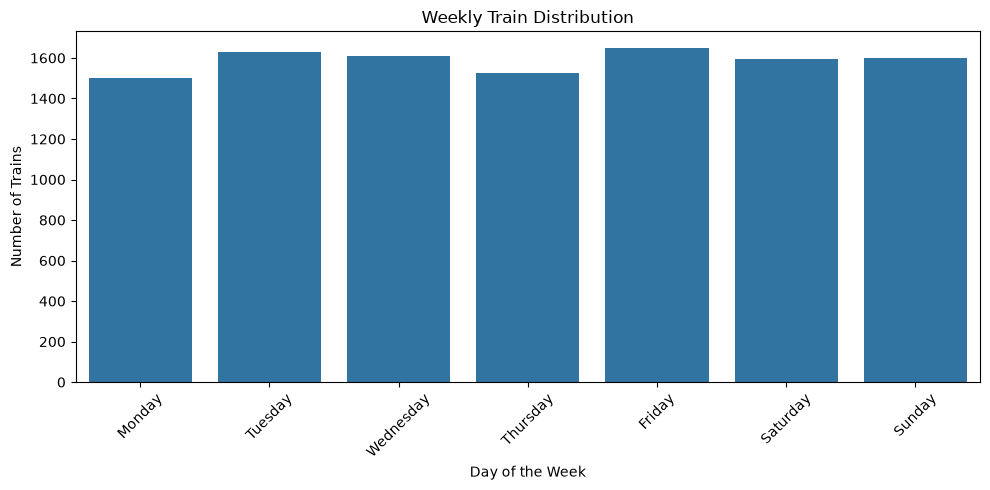

In [5]:
# Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekly_distribution,
    x="Day",
    y="Train_Count"
)

plt.title("Weekly Train Distribution")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Trains")
plt.xticks(rotation=45)

plt.tight_layout()

# Save chart
plt.savefig(
    output_dir / "weekly_train_distribution.png",
    dpi=300
)

plt.show()

In [8]:
# ==================================================
# TASK 3.1: STATION PATTERN ANALYSIS
# ==================================================

# Count trains by source station
top_source_stations = (
    df["Source_Station_Name"]
    .value_counts()
    .head(10)
)

# Count trains by destination station
top_destination_stations = (
    df["Destination_Station_Name"]
    .value_counts()
    .head(10)
)

print("TOP 10 SOURCE STATIONS")
display(top_source_stations)

print("\nTOP 10 DESTINATION STATIONS")
display(top_destination_stations)

# Save analysis results
station_analysis = pd.DataFrame({
    "Top_Source_Stations": top_source_stations.index,
    "Source_Train_Count": top_source_stations.values,
    "Top_Destination_Stations": top_destination_stations.index,
    "Destination_Train_Count": top_destination_stations.values
})

station_analysis.to_csv(
    output_dir / "station_pattern_analysis.csv",
    index=False
)

print("Station pattern analysis saved successfully!")

TOP 10 SOURCE STATIONS


Source_Station_Name
CST-MUMBAI       513
SEALDAH          372
CHENNAI BEACH    339
HOWRAH JN.       338
KALYAN JN        285
THANE            186
PANVEL           141
TAMBARAM         140
MOOR MARKET      135
VELACHEERY       115
Name: count, dtype: int64


TOP 10 DESTINATION STATIONS


Destination_Station_Name
CST-MUMBAI       514
SEALDAH          373
CHENNAI BEACH    342
HOWRAH JN.       337
KALYAN JN        284
THANE            194
PANVEL           144
TAMBARAM         140
MOOR MARKET      132
VELACHEERY       118
Name: count, dtype: int64

Station pattern analysis saved successfully!


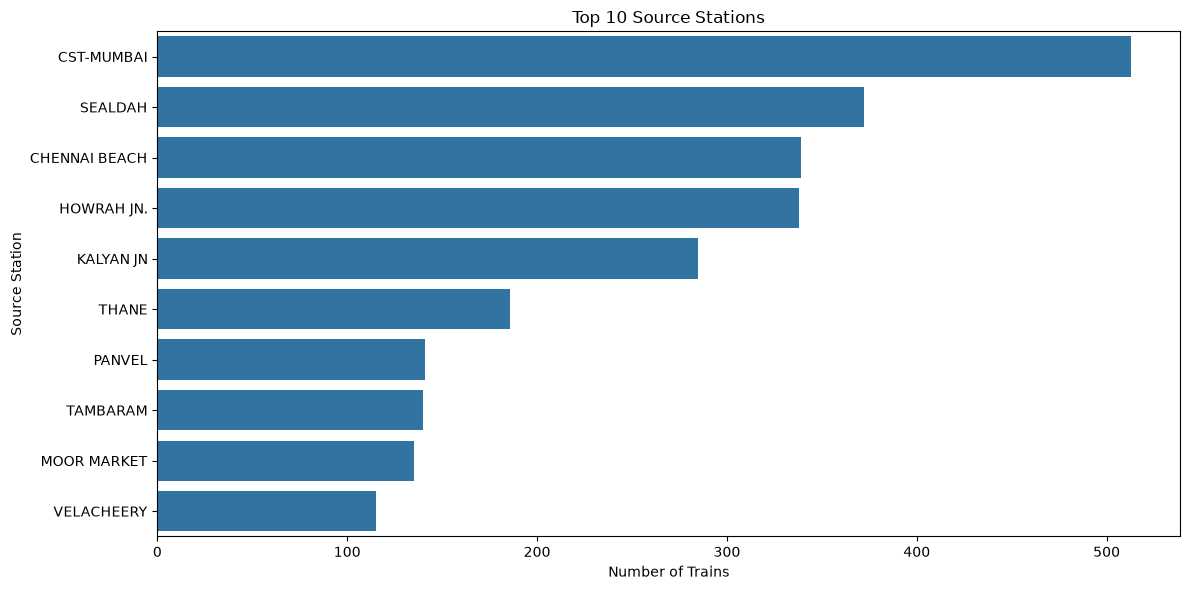

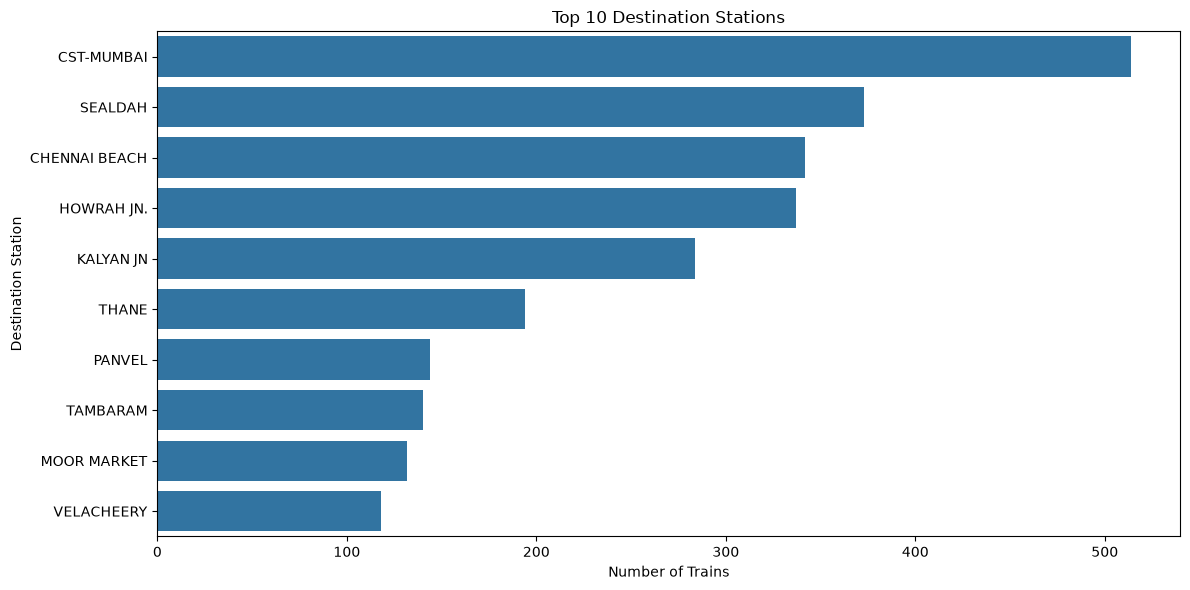

Station pattern charts saved successfully!


In [9]:
# ==================================================
# TASK 3.1: STATION PATTERN VISUALIZATION
# ==================================================

# Top 10 source stations
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_source_stations.values,
    y=top_source_stations.index
)

plt.title("Top 10 Source Stations")
plt.xlabel("Number of Trains")
plt.ylabel("Source Station")

plt.tight_layout()

plt.savefig(
    output_dir / "top_source_stations.png",
    dpi=300
)

plt.show()


# Top 10 destination stations
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_destination_stations.values,
    y=top_destination_stations.index
)

plt.title("Top 10 Destination Stations")
plt.xlabel("Number of Trains")
plt.ylabel("Destination Station")

plt.tight_layout()

plt.savefig(
    output_dir / "top_destination_stations.png",
    dpi=300
)

plt.show()

print("Station pattern charts saved successfully!")

In [10]:
# ==================================================
# TASK 3.2: CORRELATION AND INSIGHTS
# ==================================================

# Create numerical day mapping
day_mapping = {
    "Monday": 1,
    "Tuesday": 2,
    "Wednesday": 3,
    "Thursday": 4,
    "Friday": 5,
    "Saturday": 6,
    "Sunday": 7
}

# Add numerical day column
df["Day_Number"] = df["days"].map(day_mapping)

# Group train records by day
daily_analysis = (
    df.groupby(["days", "Day_Number"])
    .size()
    .reset_index(name="Train_Count")
    .sort_values("Day_Number")
)

print("DAILY TRAIN ANALYSIS")
display(daily_analysis)

# Calculate correlation
correlation = daily_analysis[
    ["Day_Number", "Train_Count"]
].corr()

print("\nCORRELATION MATRIX")
display(correlation)

# Save analysis
daily_analysis.to_csv(
    output_dir / "daily_correlation_analysis.csv",
    index=False
)

print("Daily correlation analysis saved successfully!")

DAILY TRAIN ANALYSIS


,days,Day_Number,Train_Count
1,Monday,1,1503
5,Tuesday,2,1628
6,Wednesday,3,1612
4,Thursday,4,1526
0,Friday,5,1649
2,Saturday,6,1593
3,Sunday,7,1602



CORRELATION MATRIX


,Day_Number,Train_Count
Day_Number,1.000000,0.380576
Train_Count,0.380576,1.000000


Daily correlation analysis saved successfully!


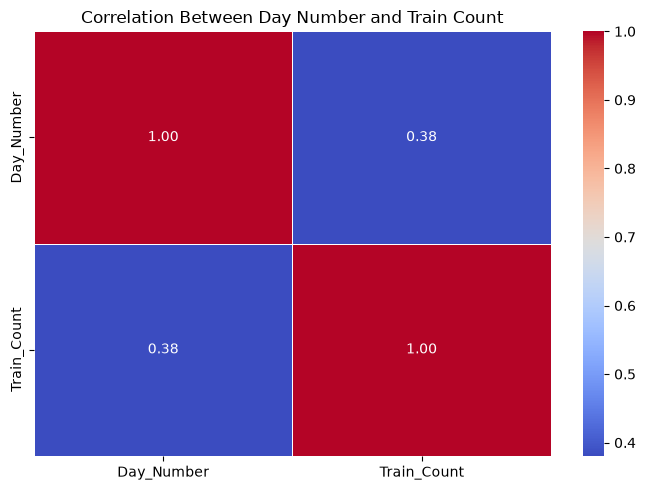

Correlation heatmap saved successfully!


In [11]:
# ==================================================
# TASK 3.2: CORRELATION VISUALIZATION
# ==================================================

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Day Number and Train Count")

plt.tight_layout()

plt.savefig(
    output_dir / "daily_correlation_heatmap.png",
    dpi=300
)

plt.show()

print("Correlation heatmap saved successfully!")

In [12]:
# ==================================================
# TASK 3.2: INSIGHTS AND RECOMMENDATIONS
# ==================================================

highest_day = daily_analysis.loc[
    daily_analysis["Train_Count"].idxmax()
]

lowest_day = daily_analysis.loc[
    daily_analysis["Train_Count"].idxmin()
]

print("KEY INSIGHTS")
print("--------------------------------")

print(
    f"Highest train activity: "
    f"{highest_day['days']} "
    f"({highest_day['Train_Count']} trains)"
)

print(
    f"Lowest train activity: "
    f"{lowest_day['days']} "
    f"({lowest_day['Train_Count']} trains)"
)

print(f"Correlation coefficient: {correlation.iloc[0, 1]:.4f}")

print("\nRECOMMENDATIONS")
print("--------------------------------")
print("1. Monitor train demand across all seven days.")
print("2. Review Friday operations due to the highest train count.")
print("3. Compare actual passenger demand before adjusting schedules.")
print("4. Investigate station-level differences for better resource planning.")

KEY INSIGHTS
--------------------------------
Highest train activity: Friday (1649 trains)
Lowest train activity: Monday (1503 trains)
Correlation coefficient: 0.3806

RECOMMENDATIONS
--------------------------------
1. Monitor train demand across all seven days.
2. Review Friday operations due to the highest train count.
3. Compare actual passenger demand before adjusting schedules.
4. Investigate station-level differences for better resource planning.
